# Two particle stimulation in a box with inverse-power potential

## 1. basic environment setup

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

In [2]:
# Standard kinetic energy: T(p) = sum p^2 / (2m)
def kinetic(p, masses):
    return sum(
        sum(p[i]**2) / (2 * masses[i])
        for i in range(len(masses))
    )

In [3]:
# Particle-particle potential plus particle-walls potential
def inverse_power_potential(q, k, alpha, C, beta, Lx, Ly):
    separation = q[0] - q[1]
    r_squared = sum(separation**2)
    particle_potential = k * r_squared**(-alpha / 2)

    wall_potential = 0
    for x, y in q:
        wall_potential += C * (
            x**(-beta)
            + (Lx - x)**(-beta)
            + y**(-beta)
            + (Ly - y)**(-beta)
        )

    return particle_potential + wall_potential

In [4]:
class System:
    def __init__(
        self,
        q0,
        p0,
        KE,
        V,
        V_parameters,
        masses=(1.0, 1.0),
    ):
        self.q = np.asarray(q0, dtype=float)
        self.p = np.asarray(p0, dtype=float)
        self.masses = np.asarray(masses, dtype=float)
        self.num_particles = len(self.q)
        self.KE = KE
        self.V = V
        self.V_parameters = dict(V_parameters)

        # Define the symbolic coordinates x1, y1, x2, y2, ...
        q_symbols = np.array([
            [sp.Symbol(f"x{i + 1}"), sp.Symbol(f"y{i + 1}")]
            for i in range(self.num_particles)
        ])

        # Build the symbolic expression V(q).
        V_symbolic = self.V(q_symbols, **self.V_parameters)

        # Compute the force F(q) = -grad V(q).
        F_symbolic = np.array([
            -sp.diff(V_symbolic, coordinate)
            for coordinate in q_symbols.ravel()
        ]).reshape(q_symbols.shape)

        # Convert the symbolic force into a numerical function:
        # force_flat(x1, y1, x2, y2, ...) returns
        # [Fx1, Fy1, Fx2, Fy2, ...].
        force_flat = sp.lambdify(
            q_symbols.ravel().tolist(),
            F_symbolic.ravel().tolist(),
            modules="numpy",
        )

        # Restore the (particle, coordinate) array shape used by q and p.
        def force(q):
            return np.asarray(
                force_flat(*q.ravel()),
                dtype=float,
            ).reshape(q.shape)

        self.force = force

    def energy(self):
        return float(
            self.KE(self.p, self.masses)
            + self.V(self.q, **self.V_parameters)
        )

    def leapfrog(self, h, nsteps):
        q_history = [self.q.copy()]
        p_history = [self.p.copy()]

        energy_history = [self.energy()]

        for _ in range(nsteps):
            # First kick
            self.p += 0.5 * h * self.force(self.q)

            # Drift
            self.q += h * self.p / self.masses[:, None]

            # Second kick
            self.p += 0.5 * h * self.force(self.q)

            q_history.append(self.q.copy())
            p_history.append(self.p.copy())

            energy_history.append(self.energy())

        return (
            np.asarray(q_history),
            np.asarray(p_history),
            np.asarray(energy_history),
        )

In [5]:
def plot_leapfrog(q, p, energy, h):
    time = h * np.arange(len(energy))

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Particle trajectories
    for i in range(q.shape[1]):
        axes[0].plot(
            q[:, i, 0],
            q[:, i, 1],
            label=f"Particle {i + 1}",
        )

    axes[0].set_xlabel("x")
    axes[0].set_ylabel("y")
    axes[0].set_title("Particle trajectories")
    axes[0].axis("equal")
    axes[0].legend()

    # Momentum
    for i in range(p.shape[1]):
        axes[1].plot(
            time,
            p[:, i, 0],
            label=f"Particle {i + 1}: px",
        )
        axes[1].plot(
            time,
            p[:, i, 1],
            "--",
            label=f"Particle {i + 1}: py",
        )

    axes[1].set_xlabel("Time")
    axes[1].set_ylabel("Momentum")
    axes[1].set_title("Momentum")
    axes[1].legend()

    # Energy error
    # axes[2].plot(time, energy - energy[0])
    # axes[2].set_xlabel("Time")
    # axes[2].set_ylabel("E(t) - E(0)")
    # axes[2].set_title("Energy error")

    plt.tight_layout()
    plt.show()

## 2. Tests for specific initial conditions

Case 1: For particles with low initial kinetic energy and initially locating near the equilibrium point, we found that particles only do very small oscillations near the equilibrium point. 

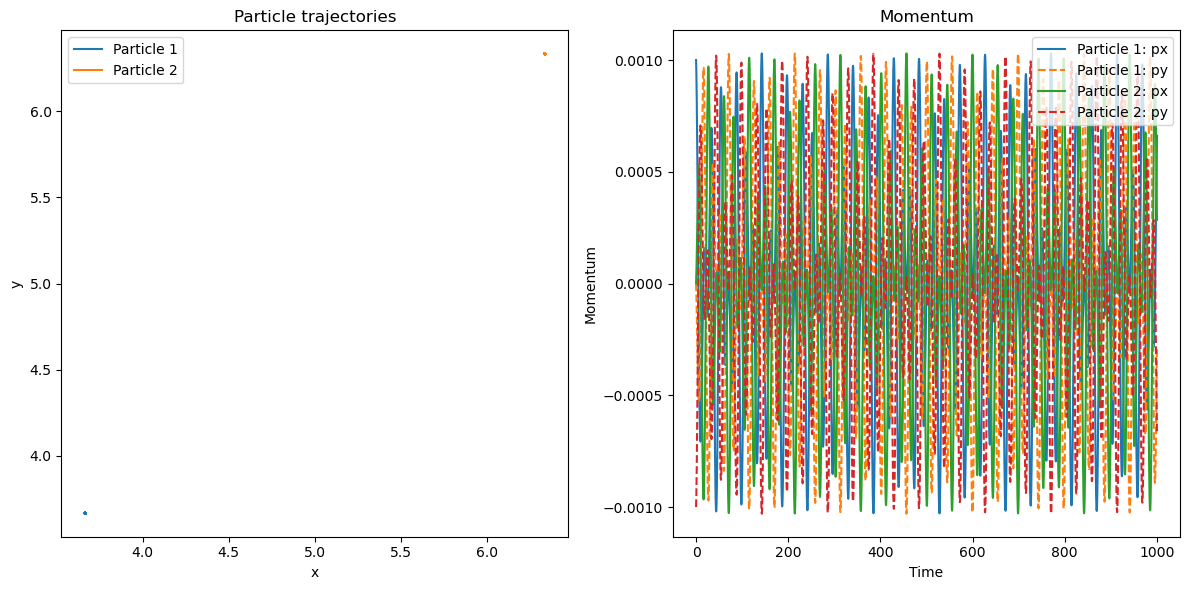

In [23]:
a = 3.6644771408428354  # found by calculating the gradient of V and set it to 0
A = 0.001  # deviation from the exact equilibrium (stationary potential) point
q0 = [
    [a + A / 2, a + A / 2],
    [10 - a - A / 2, 10 - a - A / 2],
]  # initial position
p0 = [
    [0.001, 0.000],
    [-0.000, -0.001],
]  # initial momentum
large_orbit = System(
    q0=q0,
    p0=p0,
    KE=kinetic,
    V=inverse_power_potential,
    V_parameters={
        "k": 1.0,
        "alpha": 1.0,
        "beta": 1.0,
        'C': 1.0,
        "Lx": 10.0,
        "Ly": 10.0,
    },
    masses=(1.0, 1.0),
)

h = 0.01
q, p, energy = large_orbit.leapfrog(
    h=h,
    nsteps=100000,
)

plot_leapfrog(q, p, energy, h)

We can observe the oscillations more clearly if we set the initial condition a bit further away from the equilibrium point.

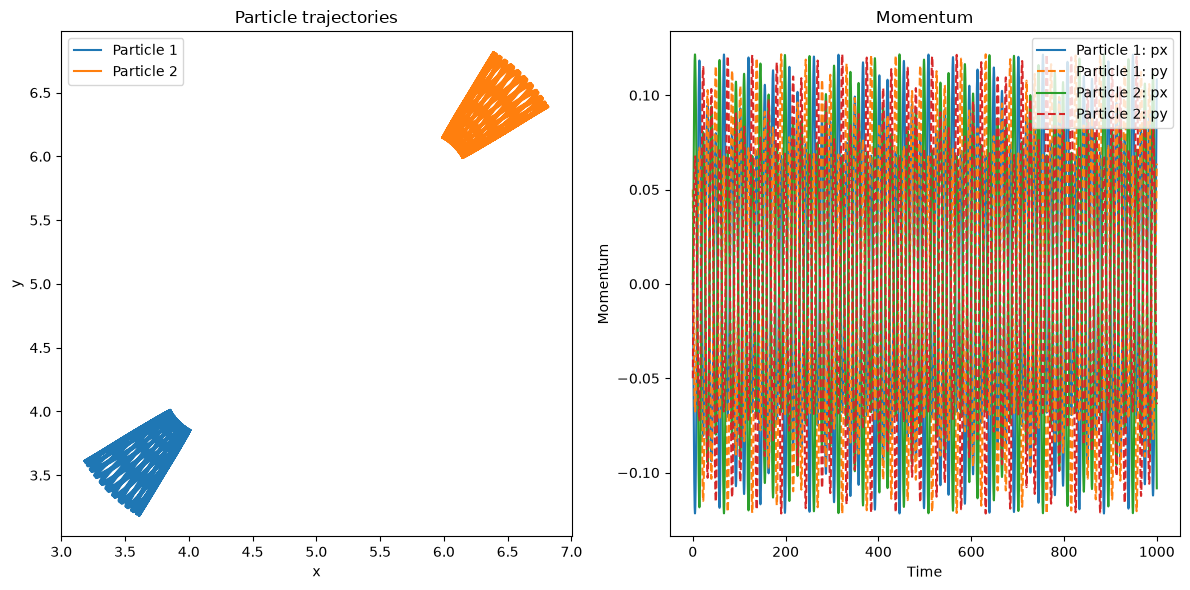

In [13]:
a = 3.6644771408428354  # found by calculating the gradient of V and set it to 0
A = 0.5  # deviation from the exact equilibrium (stationary potential) point
q0 = [
    [a + A / 2, a + A / 2],
    [10 - a - A / 2, 10 - a - A / 2],
]  # initial position
p0 = [
    [0.0, 0.05],
    [0.0, -0.05],
]  # initial momentum
large_orbit = System(
    q0=q0,
    p0=p0,
    KE=kinetic,
    V=inverse_power_potential,
    V_parameters={
        "k": 1.0,
        "alpha": 1.0,
        "beta": 1.0,
        'C': 1.0,
        "Lx": 10.0,
        "Ly": 10.0,
    },
    masses=(1.0, 1.0),
)

h = 0.01
q, p, energy = large_orbit.leapfrog(
    h=h,
    nsteps=100000,
)

plot_leapfrog(q, p, energy, h)

Case 2: For particles with slightly higher initial kinetic energy and initially locating near the equilibrium point, we set the direction of the initial velocities to be 45 degrees below and above x-axis respectively. We found that the two particles look like they are chained together and moves in a seemingly circular orbit.

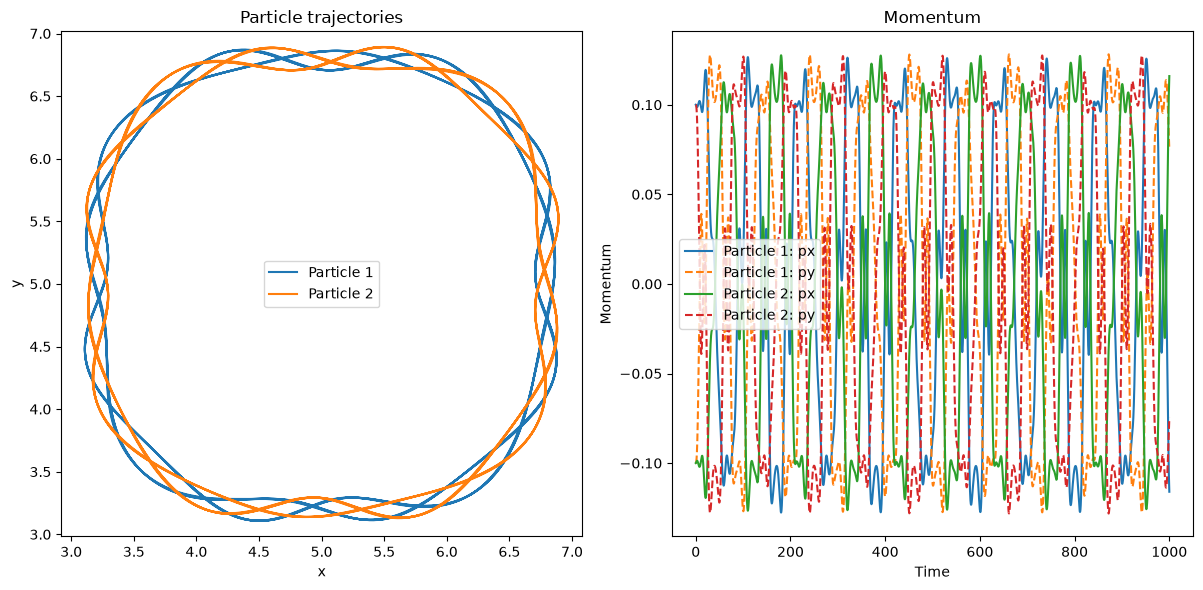

array([[6.33502286, 6.33502286],
       [6.33402286, 6.33602286],
       [6.33302287, 6.33702287],
       ...,
       [3.60447055, 3.59717425],
       [3.60562939, 3.59642585],
       [3.60678899, 3.59567822]], shape=(100001, 2))

In [11]:
a = 3.6644771408428354  # found by calculating the gradient of V and set it to 0
A = 0.001  # deviation from the exact equilibrium (stationary potential) point
q0 = [
    [a + A / 2, a + A / 2],
    [10 - a - A / 2, 10 - a - A / 2],
]  # initial position
p0 = [
    [0.1, -0.1],
    [-0.1, 0.1],
]  # initial momentum
large_orbit = System(
    q0=q0,
    p0=p0,
    KE=kinetic,
    V=inverse_power_potential,
    V_parameters={
        "k": 1.0,
        "alpha": 1.0,
        "beta": 1.0,
        'C': 1.0,
        "Lx": 10.0,
        "Ly": 10.0,
    },
    masses=(1.0, 1.0),
)

h = 0.01
q, p, energy = large_orbit.leapfrog(
    h=h,
    nsteps=100000,
)

plot_leapfrog(q, p, energy, h)

Case 3: For two particles with very high initial kinetic energies, we can theoretically compute two specific x-coordinates such that the two particles starting at these coordinates and moving up and down respectivly seems to be confined on two verticle lines. (This is no longer observable if initial KE is small)

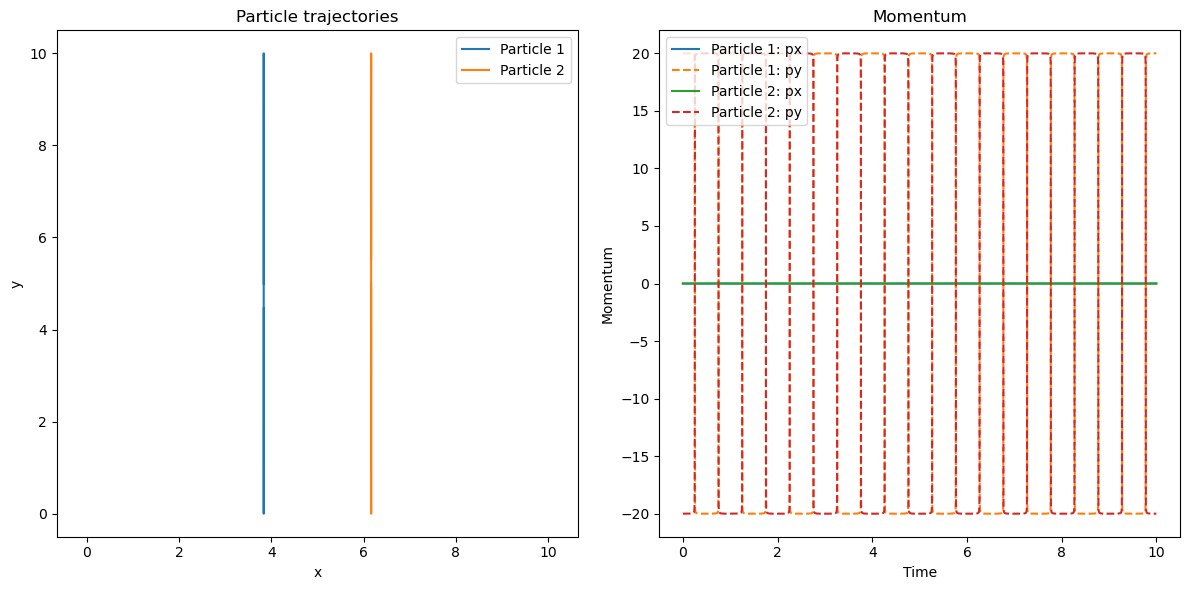

In [39]:
x_star = 3.8351644331875563
normal_mode = System(
    q0=[
        [x_star, 5.0],
        [10 - x_star, 5.0],
    ],

    p0 = [
        [0.0, 20.0],
        [0.0, -20.0],
    ],
    KE=kinetic,
    V=inverse_power_potential,
    V_parameters={
        "k": 1.0,
        "alpha": 1.0,
        "beta": 1.0,
        "C": 1.0,
        "Lx": 10.0,
        "Ly": 10.0,
    },
    masses=(1.0, 1.0),
)

h = 0.0001
q, p, energy = normal_mode.leapfrog(
    h=h,
    nsteps=100000,
)

plot_leapfrog(q, p, energy, h)

Case 4 : We slightly move the x coordinates of the previous initial conditions. Now we see the particles oscillates horizontally, but slowly.

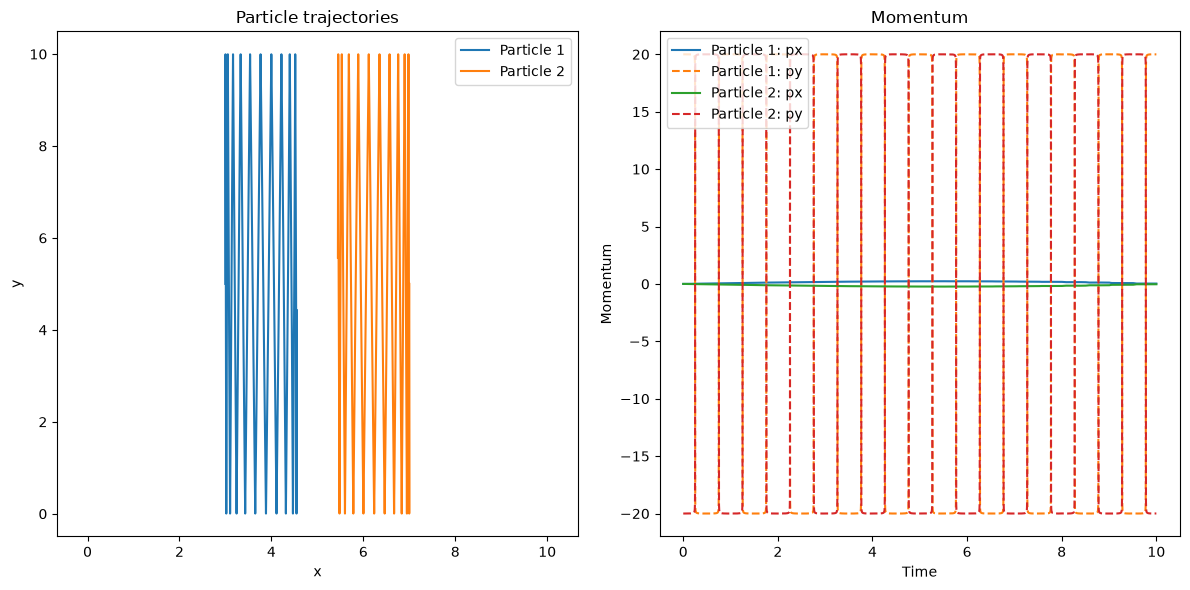

In [16]:
normal_mode = System(
    q0=[
        [3.0, 5.0],
        [10 - 3.0, 5.0],
    ],

    p0 = [
        [0.0, 20.0],
        [0.0, -20.0],
    ],
    KE=kinetic,
    V=inverse_power_potential,
    V_parameters={
        "k": 1.0,
        "alpha": 1.0,
        "beta": 1.0,
        "C": 1.0,
        "Lx": 10.0,
        "Ly": 10.0,
    },
    masses=(1.0, 1.0),
)

h = 0.0001
q, p, energy = normal_mode.leapfrog(
    h=h,
    nsteps=100000,
)

plot_leapfrog(q, p, energy, h)